импорт библиотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

In [13]:
# Загрузка датасета
df = pd.read_csv("Life Expectancy Data.csv")

df = df.drop(columns=["Country", "Year", "Population", "infant deaths"])

for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

df = pd.get_dummies(df, drop_first=True)

X = df.drop("Life expectancy ", axis=1)
y = df["Life expectancy "]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)

(2350, 17)


In [14]:
median_life_exp = y_train.median()
y_train_class = (y_train>median_life_exp).astype(int)
y_test_class = (y_test>median_life_exp).astype(int)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

display(
    pd.DataFrame(
    {
        "Вероятность (Сигмоида)":sample_probs,
        "Класс (Порог 0.5)":sample_preds,
        "Факт":y_test_class.iloc[:5].values,
    }
    ).round(3)
)

print(f"Точность классификации (Accuracy): {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.307,0,1
1,0.974,1,1
2,0.873,1,1
3,0.985,1,1
4,0.000,0,0


Точность классификации (Accuracy): 0.8895


Регрессия: МНК и SGD

In [15]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time()-start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3, eta0=0.01, learning_rate="adaptive", random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time()-start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f" МНК (Аналитический): RMSE = {rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:.5f} сек")
print(f" SGD (Итеративный): RMSE = {rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:.5f} сек")

 МНК (Аналитический): RMSE = 4.04 | R2 = 0.81 | Время = 0.00482 сек
 SGD (Итеративный): RMSE = 4.04 | R2 = 0.81 | Время = 0.01767 сек


И аналитическая и итеративная модель показывают одинаковые результаты за исключением времени - аналитическая модель работает быстрее, чем итеративная

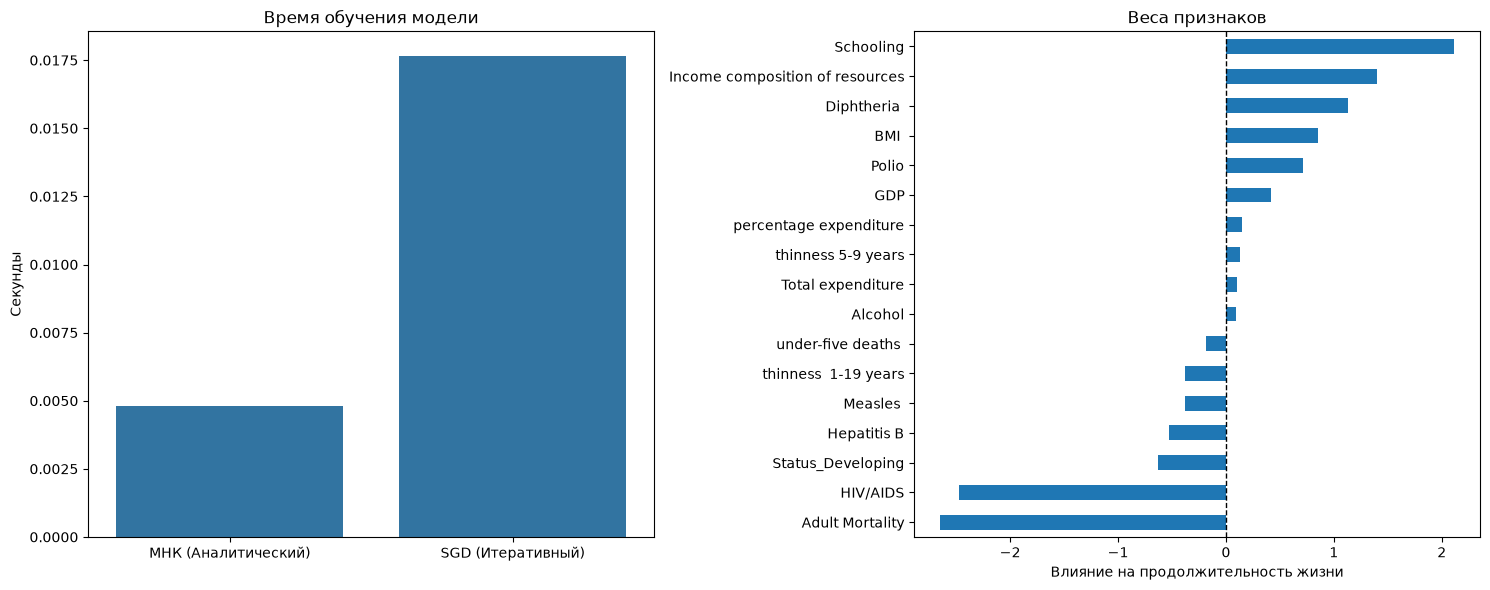

In [16]:
fig, axes = plt.subplots(1,2, figsize=(15,6))
#Сравнение времени выполнения
sns.barplot(
    x=["МНК (Аналитический)", "SGD (Итеративный)"],
    y = [time_ols, time_sgd],
    ax = axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")

weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])
axes[1].set_title("Веса признаков")
axes[1].set_xlabel("Влияние на продолжительность жизни")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

Первый график визуализирует, что аналитическая модель работает быстрее итеративной

Второй график показывает какие признаки влияют на продолжительность жизни. По нему можно сделать вывод, что на продолжительность жизни положительно влияет сильнее всего количество лет образования, а также индекс человеческого развития, вакцинация от дифтерии, индекс массы тела. Отрицательно влияют сильнее смертность взрослых, смертность от ВИЧ и СПИД